# 001 — Are returns predictable? Is volatility?

**Hypotheses**

- **H1** Daily returns are (almost) serially uncorrelated: past returns barely predict
  future returns.
- **H2** Absolute returns are strongly and persistently autocorrelated: volatility *is*
  predictable.
- **H3** The small return autocorrelation that once existed has faded over time (markets
  adapt once a pattern is known and traded).

**Data**: S&P 500 index (`^GSPC`, 1962 → today) for the long history, and the iShares MSCI
World ETF (`IWDA.AS`, 2009 → today) as the asset actually held. Log returns from adjusted
prices.

**Rules**: every forecast is out-of-sample: the value at date *t* only uses data up to *t*
and is scored against what happens after *t*.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fin.data import load_market_data
from fin.plotting import SERIES, use_style
from fin.signals import annualize, ewma_vol, garch_vol, rolling_vol
from fin.stats import (
    acf,
    acf_band,
    ljung_box,
    mincer_zarnowitz,
    next_period,
    oos_r2,
    qlike,
    variance_ratio_table,
)

use_style()
pd.set_option("display.float_format", "{:.4f}".format)

md = load_market_data(["^GSPC", "IWDA.AS"], start="1962-01-01")
r = md.returns()
assets = {"S&P 500": r["^GSPC"].dropna(), "MSCI World (IWDA)": r["IWDA.AS"].dropna()}
spx = assets["S&P 500"]
{name: f"{s.index[0].date()} → {s.index[-1].date()} ({len(s)} days)" for name, s in assets.items()}

{'S&P 500': '1962-01-03 → 2026-10-23 (16311 days)',
 'MSCI World (IWDA)': '2009-09-28 → 2026-10-23 (4370 days)'}

## 1. Stylized facts

Before testing anything: what do the returns look like? Two features matter for everything
below: **heavy tails** (excess kurtosis far above the Gaussian 0) and **volatility
clustering** (turbulent days come in bursts).

In [2]:
pd.DataFrame(
    {
        name: {
            "ann. mean": s.mean() * 252,
            "ann. vol": annualize(s.std()),
            "skew": s.skew(),
            "excess kurtosis": s.kurt(),
            "worst day": s.min(),
            "best day": s.max(),
        }
        for name, s in assets.items()
    }
)

,S&P 500,MSCI World (IWDA)
ann. mean,0.0723,0.1173
ann. vol,0.1649,0.1513
skew,-0.9438,-0.6428
excess kurtosis,24.7111,7.0947
worst day,-0.2290,-0.0935
best day,0.1096,0.0805


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


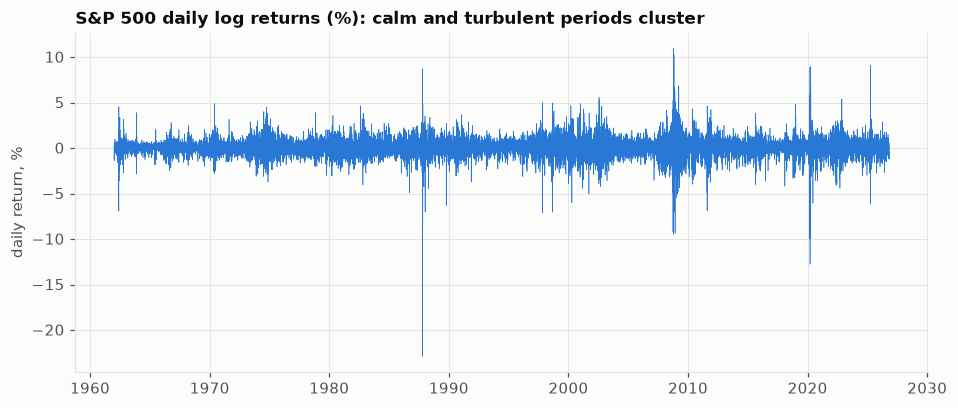

In [3]:
fig, ax = plt.subplots()
ax.plot(spx.index, spx * 100, lw=0.4, color=SERIES[0])
ax.set_title("S&P 500 daily log returns (%): calm and turbulent periods cluster")
ax.set_ylabel("daily return, %")
plt.show()

## 2. Autocorrelation: returns vs absolute returns (H1, H2)

If returns were i.i.d., the sample ACF at each lag would be ~N(0, 1/n): inside the
dashed band 95% of the time. We compare the ACF of $r_t$ with the ACF of $|r_t|$.

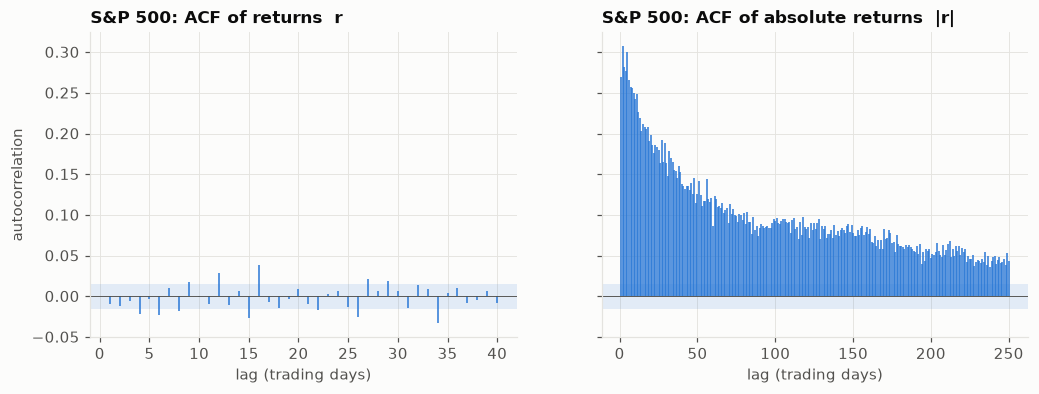

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (label, x, nlags) in zip(
    axes, [("returns  r", spx, 40), ("absolute returns  |r|", spx.abs(), 250)], strict=True
):
    a = acf(x, nlags)
    band = acf_band(len(x))
    ax.vlines(a.index, 0, a.values, color=SERIES[0], lw=1)
    ax.axhspan(-band, band, color=SERIES[0], alpha=0.12, lw=0)
    ax.axhline(0, color="#52514e", lw=0.6)
    ax.set_title(f"S&P 500: ACF of {label}")
    ax.set_xlabel("lag (trading days)")
axes[0].set_ylabel("autocorrelation")
plt.show()

In [5]:
pd.concat(
    {
        f"{name} {kind}": ljung_box(x, lags=[5, 10, 20])
        for name, s in assets.items()
        for kind, x in [("r", s), ("|r|", s.abs())]
    },
    axis=1,
)

S&P 500 r         S&P 500 |r|         MSCI World (IWDA) r          \
            Q p_value           Q p_value                   Q p_value   
lag                                                                     
5     12.2318  0.0317   6740.6597  0.0000              2.7561  0.7375   
10    32.4041  0.0003  12034.8148  0.0000             18.7244  0.0439   
20    91.2484  0.0000  19419.6977  0.0000             38.6223  0.0074   

    MSCI World (IWDA) |r|          
                        Q p_value  
lag                                
5               1106.1870  0.0000  
10              1873.5165  0.0000  
20              2651.3960  0.0000

## 3. Variance ratio test (H1, H3)

Lo & MacKinlay (1988): for a random walk, the variance of q-day returns is q times the
variance of 1-day returns, so $VR(q) = 1$. $VR > 1$ means trending (positive
autocorrelation), $VR < 1$ mean reversion. We use the heteroskedasticity-robust z, since
section 2 shows the variance is anything but constant.

In [6]:
pd.concat(
    {name: variance_ratio_table(s, qs=[2, 5, 10, 20, 60]) for name, s in assets.items()},
    axis=1,
).loc[:, (slice(None), ["vr", "z_robust", "p_value"])]

S&P 500                  MSCI World (IWDA)                 
        vr z_robust p_value                vr z_robust p_value
q                                                             
2   0.9906  -0.4869  0.6263            0.9893  -0.3833  0.7015
5   0.9576  -0.9763  0.3289            0.9797  -0.3482  0.7277
10  0.9116  -1.3718  0.1701            0.9549  -0.5119  0.6087
20  0.9005  -1.1177  0.2637            0.9265  -0.5823  0.5603
60  0.8560  -1.0594  0.2894            0.7130  -1.4323  0.1521

Is the dependence stable over time? Same test, decade by decade (H3).

In [7]:
by_decade = {}
for decade, s in spx.groupby((spx.index.year // 10) * 10):
    t = variance_ratio_table(s, qs=[2, 5])
    by_decade[f"{decade}s"] = {
        "lag-1 autocorr": s.autocorr(1),
        "VR(2)": t.loc[2, "vr"],
        "z(2)": t.loc[2, "z_robust"],
        "VR(5)": t.loc[5, "vr"],
        "z(5)": t.loc[5, "z_robust"],
        "days": len(s),
    }
pd.DataFrame(by_decade).T

,lag-1 autocorr,VR(2),z(2),VR(5),z(5),days
1960s,0.1784,1.1794,3.2467,1.3201,2.9614,1986.0000
1970s,0.2498,1.2504,9.2210,1.4065,6.8119,2526.0000
1980s,0.0517,1.0517,0.8345,0.9875,-0.0906,2528.0000
1990s,0.0172,1.0173,0.5428,0.9797,-0.3112,2528.0000
2000s,-0.0862,0.9143,-2.5341,0.7980,-2.5027,2515.0000
2010s,-0.0460,0.9542,-1.4236,0.9060,-1.2804,2516.0000
2020s,-0.1631,0.8377,-2.2631,0.8237,-1.1357,1712.0000


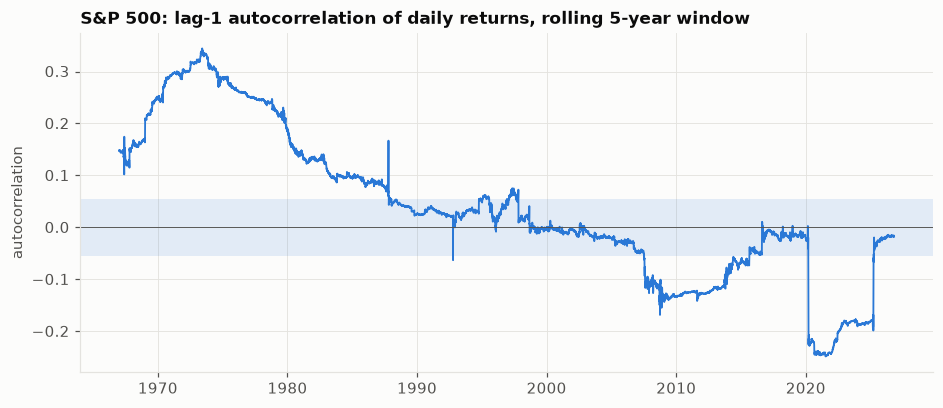

In [8]:
window = 5 * 252
rolling_rho = spx.rolling(window).corr(spx.shift(1))
band = acf_band(window)
fig, ax = plt.subplots()
ax.plot(rolling_rho.index, rolling_rho, color=SERIES[0])
ax.axhspan(-band, band, color=SERIES[0], alpha=0.12, lw=0)
ax.axhline(0, color="#52514e", lw=0.6)
ax.set_title("S&P 500: lag-1 autocorrelation of daily returns, rolling 5-year window")
ax.set_ylabel("autocorrelation")
plt.show()

## 4. Volatility forecasting, out-of-sample (H2)

Four forecasters of tomorrow's variance, all using only data up to today:

| model | idea |
|---|---|
| **historical** | expanding-window average of $r^2$: "volatility is constant" (the baseline) |
| **rolling 21d** | sample variance of the last month |
| **EWMA** | RiskMetrics, λ = 0.94: a one-pole IIR low-pass on $r^2$ |
| **GARCH(1,1)** | same IIR filter plus a mean-reversion term, parameters re-fit yearly |

Targets: next-day $r^2$ (very noisy proxy) and the mean of $r^2$ over the next 21 days.
Scores: Mincer-Zarnowitz $R^2$ (higher is better) and QLIKE loss (lower is better).

In [9]:
def vol_forecasts(s: pd.Series) -> pd.DataFrame:
    return pd.DataFrame(
        {
            "historical": s.pow(2).expanding(252).mean(),
            "rolling 21d": rolling_vol(s, 21) ** 2,
            "EWMA": ewma_vol(s) ** 2,
            "GARCH(1,1)": garch_vol(s, min_obs=1000, refit_every=252) ** 2,
        }
    ).dropna()


def score_vol(s: pd.Series, forecasts: pd.DataFrame) -> pd.DataFrame:
    rows = {}
    for horizon in (1, 21):
        target = next_period(s**2, horizon)
        for name, f in forecasts.items():
            rows[(f"{horizon}d", name)] = {
                "MZ R2": mincer_zarnowitz(target, f)["r2"],
                "MZ slope b": mincer_zarnowitz(target, f)["b"],
                "QLIKE": qlike(target, f),
            }
    return pd.DataFrame(rows).T


vol_f = {name: vol_forecasts(s) for name, s in assets.items()}
pd.concat({name: score_vol(assets[name], f) for name, f in vol_f.items()}, axis=1)

S&P 500                    MSCI World (IWDA)             \
                  MZ R2 MZ slope b   QLIKE             MZ R2 MZ slope b   
1d  historical   0.0023     1.2764 -8.0682            0.0000     0.0283   
    rolling 21d  0.0700     0.6123 -8.4131            0.0965     0.6593   
    EWMA         0.0870     0.7981 -8.4600            0.1213     0.8446   
    GARCH(1,1)   0.0981     0.7946 -8.4745            0.1534     1.0148   
21d historical   0.0107     1.1775 -8.0592            0.0040    -1.1816   
    rolling 21d  0.1707     0.4074 -8.2477            0.1743     0.4246   
    EWMA         0.2013     0.5175 -8.3078            0.2086     0.5307   
    GARCH(1,1)   0.2108     0.4965 -8.3269            0.2582     0.6308   

                         
                  QLIKE  
1d  historical  -8.2706  
    rolling 21d -8.4632  
    EWMA        -8.5264  
    GARCH(1,1)  -8.5701  
21d historical  -8.2582  
    rolling 21d -8.2295  
    EWMA        -8.3358  
    GARCH(1,1)  -8.3981

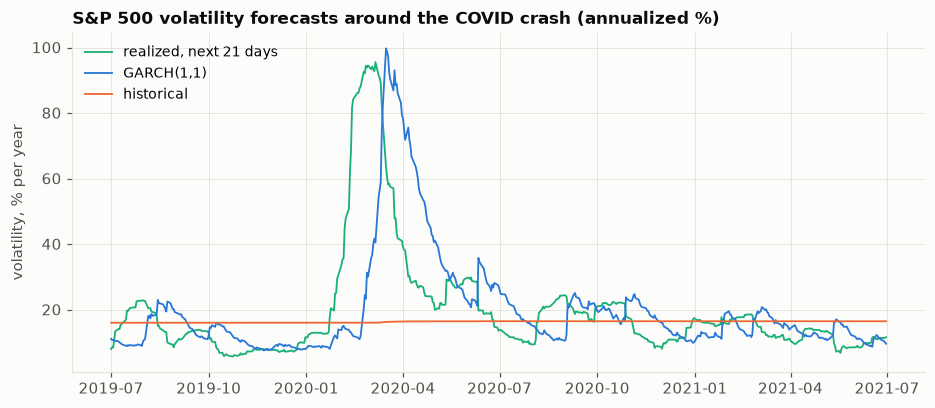

In [10]:
f = vol_f["S&P 500"].loc["2019-07":"2021-06"]
realized = np.sqrt(next_period(spx**2, 21)).loc[f.index]
fig, ax = plt.subplots()
ax.plot(realized.index, annualize(realized) * 100, color=SERIES[2], label="realized, next 21 days")
ax.plot(f.index, annualize(np.sqrt(f["GARCH(1,1)"])) * 100, color=SERIES[0], label="GARCH(1,1)")
ax.plot(f.index, annualize(np.sqrt(f["historical"])) * 100, color=SERIES[1], label="historical")
ax.set_title("S&P 500 volatility forecasts around the COVID crash (annualized %)")
ax.set_ylabel("volatility, % per year")
ax.legend(loc="upper left")
plt.show()

## 5. Return forecasting, out-of-sample (H1)

The fair comparison: the same simple model (AR(1), coefficients re-estimated every day on
an expanding window) used to predict **tomorrow's return** vs **tomorrow's absolute
return**. Score: Campbell-Thompson out-of-sample $R^2$ against the historical mean
(positive = beats "just use the average").

In [11]:
def expanding_ar1_forecast(y: pd.Series, min_obs: int = 1000) -> pd.Series:
    """Forecast of y[t+1] made at t: a_t + b_t * y[t], OLS on pairs (y[s-1], y[s]) with s <= t."""
    x, z = y.shift(1), y
    valid = x.notna() & z.notna()
    x, z = x.where(valid), z.where(valid)
    n = valid.cumsum()
    mx, mz = x.expanding().mean(), z.expanding().mean()
    cov = (x * z).expanding().mean() - mx * mz
    var = (x * x).expanding().mean() - mx**2
    b = cov / var
    a = mz - b * mx
    return (a + b * y).where(n >= min_obs)


def score_returns(s: pd.Series) -> dict:
    out = {}
    for label, y in [("r", s), ("|r|", s.abs())]:
        target = next_period(y, 1)
        hist_mean = y.expanding(1000).mean()
        out[f"OOS R2 for {label}"] = oos_r2(target, expanding_ar1_forecast(y), hist_mean)
    return out


pd.DataFrame({name: score_returns(s) for name, s in assets.items()})

,S&P 500,MSCI World (IWDA)
OOS R2 for r,-0.0016,-0.0024
OOS R2 for |r|,0.0678,0.0732


## 6. Conclusions

Numbers quoted from the run on data to 2026-10-23.

**H1 (returns ≈ unpredictable): supported.**
- The return ACF stays within or near the i.i.d. band. Ljung-Box does reject for the S&P 500
  at 10–20 lags, but it assumes i.i.d. data and over-rejects under volatility clustering.
  The heteroskedasticity-robust variance ratio test rejects at **no** horizon (all
  |z| < 1.5, both assets).
- Out-of-sample, an AR(1) forecast of tomorrow's return is **worse** than the historical
  mean (OOS R² ≈ −0.2%). Statistically visible ≠ exploitable.

**H2 (volatility is predictable): strongly supported.**
- ACF of |r| ≈ 0.3 at lag 1 and still ≈ 0.05 after 250 days: long memory, a slow
  (roughly hyperbolic) decay rather than GARCH's exponential one.
- The same AR(1) that fails on returns gets OOS R² ≈ +7% on |r|.
- GARCH(1,1) explains ~21% (S&P) / ~26% (MSCI World) of next-month realized variance; the
  constant-volatility baseline explains ~0%. Ranking by QLIKE: GARCH < EWMA < rolling 21d <
  historical, on both assets and horizons.
- Around COVID, GARCH lags the shock (it's a causal filter, so there's phase delay) but adapts within
  days, while "historical" never moves.
- MZ slopes < 1, especially at 21 days: the forecasts over-react. Partly because a
  1-step forecast is used for a 21-day horizon without GARCH's mean reversion.

**H3 (dependence fades over time): supported, with a caveat.**
- Lag-1 autocorrelation: +0.18 / +0.25 in the 1960s/70s, ~0 in the 1980s/90s, negative
  since the 2000s (VR(2) significant at both ends).
- Caveat: much of the early positive autocorrelation is a known measurement artifact of
  indices (non-synchronous trading: stale prices of illiquid constituents), not a tradable
  effect, since the index itself couldn't be traded back then.
- The rolling chart jumps when one crash day (Oct 1987, Mar 2020) enters or leaves the
  window: with excess kurtosis ≈ 25, Pearson autocorrelation is fragile.

**So what**
- The predictable part of the market is its **risk**, not its direction. The natural first
  strategy to test is **volatility targeting**: scale exposure by target_vol / forecast_vol
  (Moreira & Muir, 2017, *Volatility-Managed Portfolios*) against buy-and-hold and DCA.
- Nothing here argues for changing a long-term DCA.

**Follow-ups**
- HAR-RV model (Corsi, 2009) to capture the long memory GARCH(1,1) misses.
- Proper multi-step GARCH forecasts for the 21-day horizon.
- Robust autocorrelation (rank-based, or after volatility normalization r/σ̂) for H3.
- L1 trend filtering for regime detection (planned for Phase 2).